# Data Analysis


In this section of the notebook the provided dataset is examined to check its characteristics in order to take the right decisions in training phase 

### Get Samples

Imports the project modules from `src/` and the shared `config`, finds all the sample folders in `../data/train`, and prints how many samples were found and the first few paths.

In [12]:
import matplotlib.pyplot as plt
import sys
sys.path.append("..")          
from src.data import *
from src import config


data = download_dataset("../data/train")
print(f"Number of data: {len(data)}")
print(f"Type of data: {type(data).__name__}")
print(f"Number of elements in data: {len(data)}")
print(f"First 5 data paths: {data[:5]}")

Number of data: 931
Type of data: list
Number of elements in data: 931
First 5 data paths: [WindowsPath('../data/train/0000'), WindowsPath('../data/train/0001'), WindowsPath('../data/train/0002'), WindowsPath('../data/train/0003'), WindowsPath('../data/train/0004')]


### Visual Inspection

Reads the colour palette stored in the label PNGs and shows two samples (RGB image and colour-coded mask), to check that the data loads correctly and to identify the classes visually.

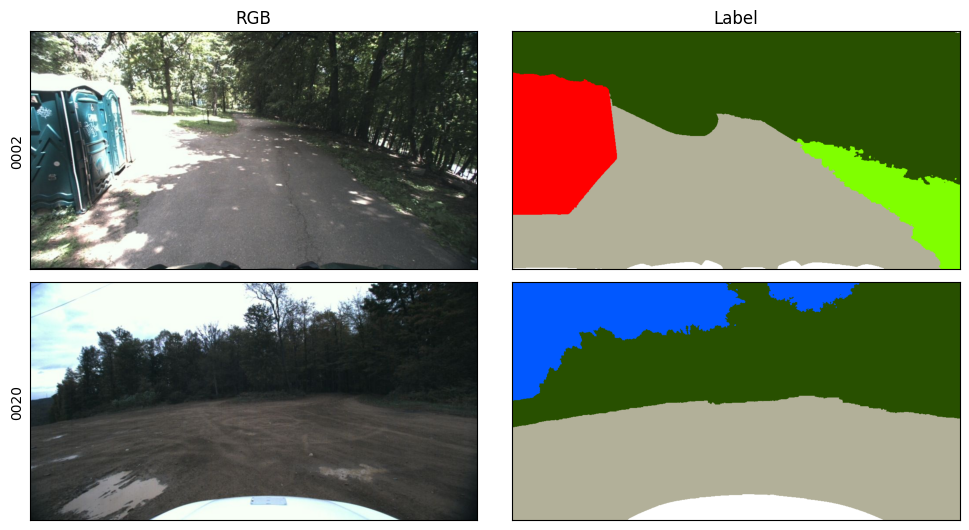

In [13]:

palette = get_palette(data[0])
_ = plot_samples(data, [2, 20], palette)      # _ = to avoid printing the matplotlib object twice in the notebook

### Dataset Statistics

A single cell, in four blocks:
- **Global statistics**: number of images, whether they all have the same size, per-channel mean and standard deviation, and a per-class summary table.
- **Class distribution**: pixel share and image presence of every class, plus inverse-frequency weights (exploratory only: the weights used in training are computed from the training split in `src/losses.py`).
- **Co-occurrence and spatial prior**: which classes appear together and where in the image each class tends to be.
- **Leakage analysis**: how similar the frames are as a function of their ID distance, which gives the decorrelation lag used by the split.

Details and conclusions: [docs/data_analysis_&_split.md](../docs/data_analysis_&_split.md)

Analysing dataset:   0%|          | 0/931 [00:00<?, ?it/s]

##### DATASET STATS #####
931 images, size (544, 1024), all equal: True
RGB mean [0.43  0.449 0.425], std [0.266 0.265 0.267]



#### CLASS DISTRIBUTION ####

[0.   0.08 0.08 0.07 6.14 1.3  0.18 0.03 0.11]


,name,pixel_%,images_%,cover_when_present_%,weight
0,background,2.86,100.00,2.86,0.00
1,smooth trail,15.04,58.97,25.51,0.08
2,traversable grass,13.36,68.96,19.38,0.08
3,rough trail,15.20,55.85,27.21,0.07
4,puddle,0.18,4.51,4.08,6.14
5,obstacle,0.87,17.62,4.91,1.30
6,non-traversable low vegetation,6.24,38.13,16.37,0.18
7,high vegetation,36.06,99.14,36.37,0.03
8,sky,10.19,90.66,11.24,0.11





#### CO-OCCURRENCE MATRIX ####




#### LEAKAGE ANALYSIS ####
 How similare are frames as a function of their ID distance


Thumbnails:   0%|          | 0/931 [00:00<?, ?it/s]

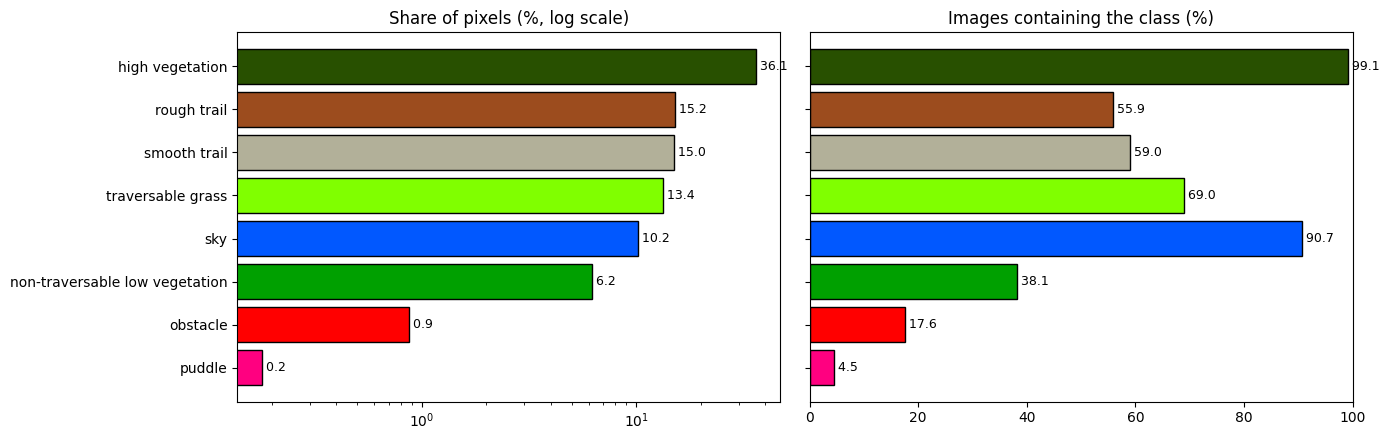

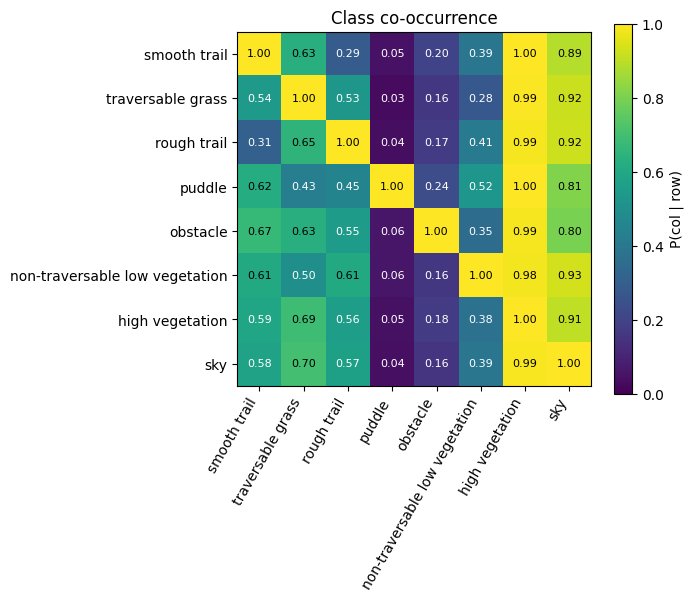

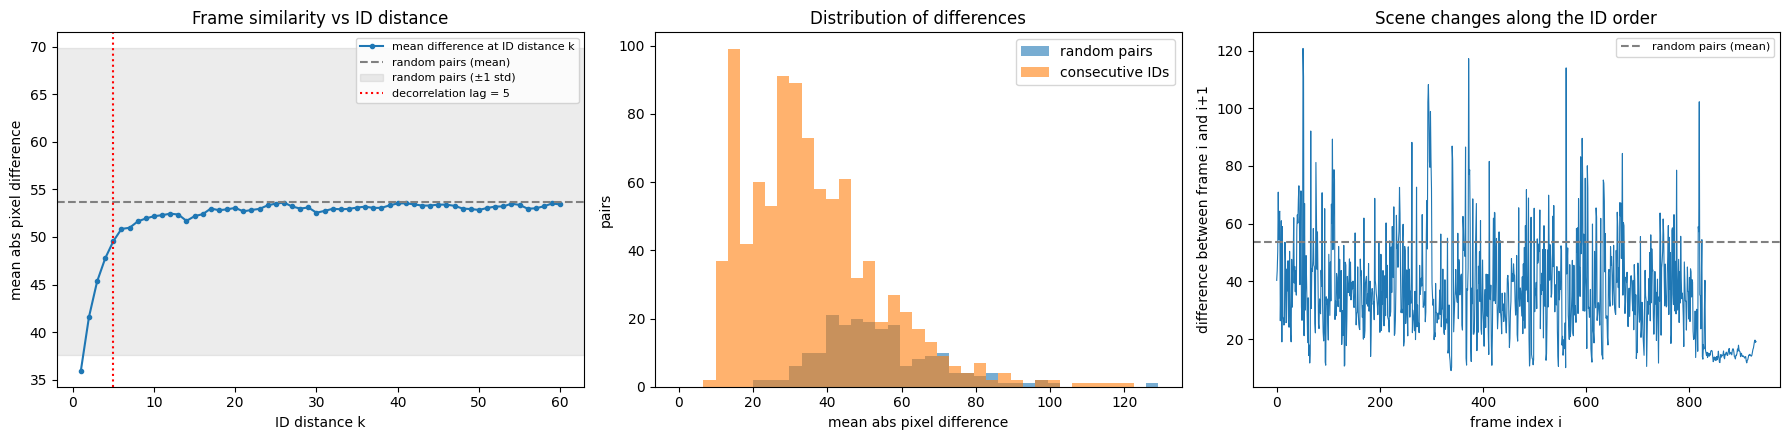

Decorrelation lag: 5
Mean difference, consecutive frames: 36.0
Mean difference, random pairs: 53.7


Spatial prior:   0%|          | 0/931 [00:00<?, ?it/s]

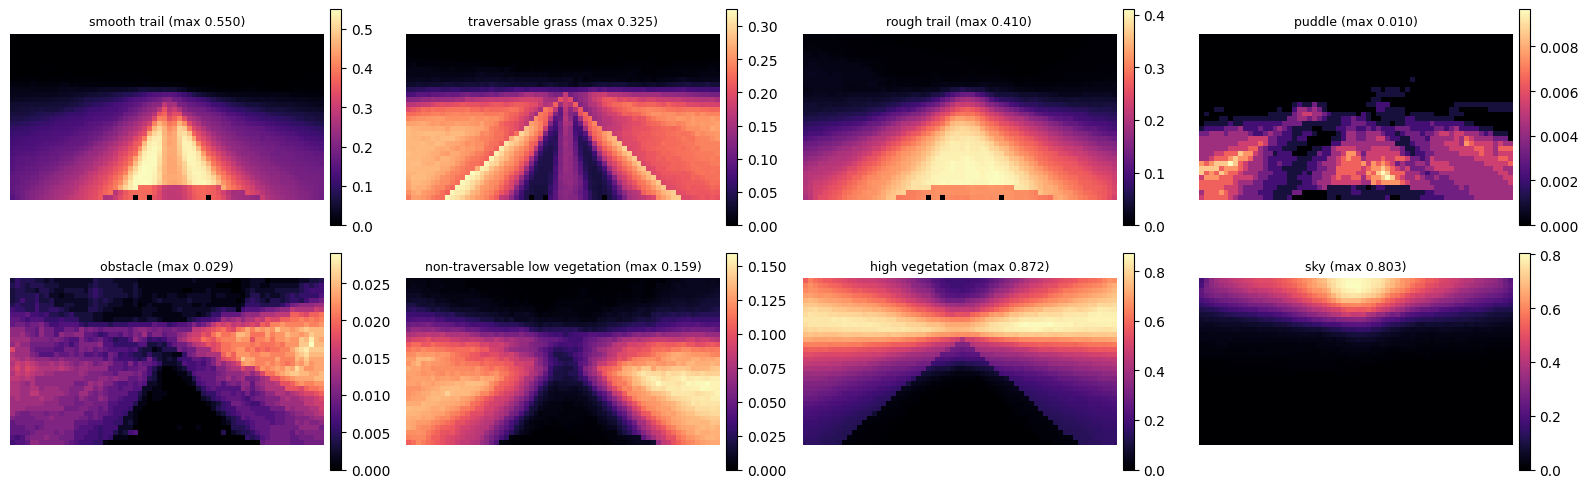

In [14]:
stats = compute_dataset_stats(data)

print("##### DATASET STATS #####")
print(f"{len(data)} images, size {tuple(stats['shapes'][0])}, " f"all equal: {len(set(map(tuple, stats['shapes']))) == 1}")
print(f"RGB mean {stats['rgb_mean'].round(3)}, std {stats['rgb_std'].round(3)}")

print("\n\n\n#### CLASS DISTRIBUTION ####\n")
plot_class_distribution(stats, palette)
print(class_weights(stats["pixel_counts"]).round(2))
display(class_summary(stats))

print("\n\n\n#### CO-OCCURRENCE MATRIX ####\n")
plot_cooccurrence(stats)

print("\n\n\n#### LEAKAGE ANALYSIS ####\n How similare are frames as a function of their ID distance")
# Leakage check
cons, rnd, thumbs = consecutive_similarity(data)
fig, lag = plot_leakage_analysis(cons, rnd, thumbs)
plt.show()
print(f"Decorrelation lag: {lag}")
print(f"Mean difference, consecutive frames: {cons.mean():.1f}")
print(f"Mean difference, random pairs: {rnd.mean():.1f}")
# Spatial prior (separate cell, so the figures do not mix)
fig = plot_spatial_prior(spatial_prior(data))
plt.show()





## Data Split

In this section of the notebook the dataset is split based on the analysis done in the previous sections

The cell builds contiguous blocks of frames, assigns whole blocks to train or validation balancing the class distribution, and purges the training frames next to the validation blocks. It then prints the size of the sets and a per-class comparison table, plots the split along the frame order, and saves it to `../data/splits/split_seed42.json`. All the parameters come from `src/config.py`.

Details: [docs/data_analysis_&_split.md](../docs/data_analysis_&_split.md)

train: 690, val: 186, purged: 55


,name,train_pixel_%,val_pixel_%,train_images,val_images
1,smooth trail,15.64,16.61,427,101
2,traversable grass,13.57,13.66,484,117
3,rough trail,15.55,14.80,370,114
4,puddle,0.21,0.16,33,8
5,obstacle,0.95,0.89,118,33
6,non-traversable low vegetation,6.29,5.98,261,70
7,high vegetation,37.33,37.40,684,184
8,sky,10.46,10.49,644,153


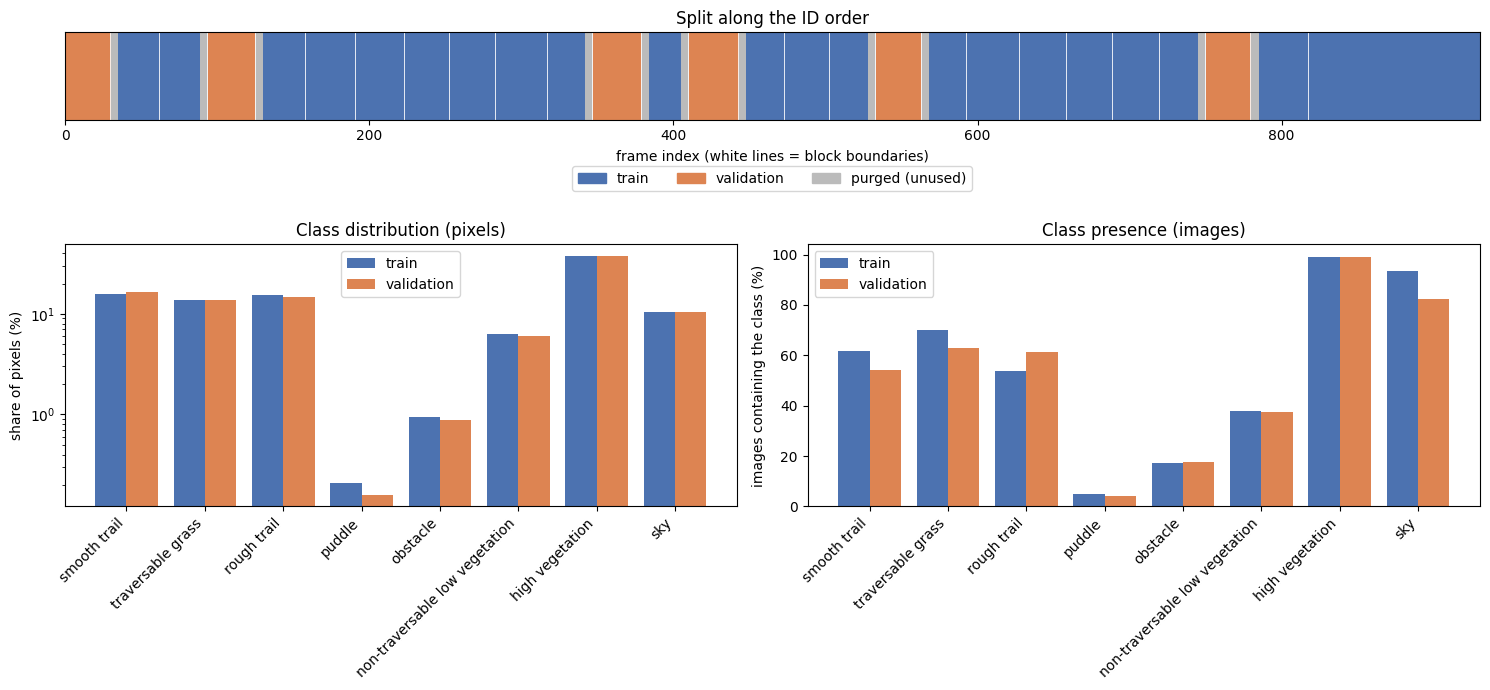

Split saved to ..\data\splits\split_seed42.json


In [15]:
from src.split import make_split, split_report, plot_split, save_split

names = [p.name for p in data]
split = make_split(names, stats["per_image"], cons, val_fraction=config.VAL_SPLIT, min_block_size=config.MIN_BLOCK_SIZE, max_block_size=config.MAX_BLOCK_SIZE, purge_gap=config.PURGE_GAP, seed=config.SEED)

print(f"train: {len(split.train_indices)}, val: {len(split.val_indices)}, purged: {len(split.purged_indices)}")
display(split_report(split, stats["per_image"]))
fig = plot_split(split, stats["per_image"])
plt.show()

save_split(split, "../data/splits/split_seed42.json")